<a href="https://colab.research.google.com/github/nobe6i/machine_learning_class/blob/main/Nora_Cook_BAN_674_HW_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BAN 674 Machine Learning: Homework 3
### Linear regression with dummy variables, k-NN classification, and k-NN for auction prediction

**Required data files**:
- `ToyotaCorolla.csv`
- `UniversalBank.csv`
- `eBayAuctions.csv`

The datasets come with the textbook. Register at https://www.dataminingbook.com/user/register to download them.

**By Nora Cook**

**Sections:** 1. Toyota dummy variables  2. Universal Bank k-NN  3. eBay auctions k-NN  4. Drishya AI Labs case

In [1]:
pip install pgeocode

In [2]:
!gdown 1g2tYxzw_4C6d_kYJvI5D0vYQt5zQ5un_
!gdown 1RlRAimYCfkU0XHkNuG6a9yJS-UJBzF_7
!gdown 1VU1hJzUdM_jT84aRQRkv7MAOeZ30XMQD

Downloading...
From: https://drive.google.com/uc?id=1g2tYxzw_4C6d_kYJvI5D0vYQt5zQ5un_
To: /content/eBayAuctions.csv
100% 81.4k/81.4k [00:00<00:00, 19.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=1RlRAimYCfkU0XHkNuG6a9yJS-UJBzF_7
To: /content/ToyotaCorolla.csv
100% 227k/227k [00:00<00:00, 26.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=1VU1hJzUdM_jT84aRQRkv7MAOeZ30XMQD
To: /content/UniversalBank.csv
100% 212k/212k [00:00<00:00, 23.7MB/s]


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from datetime import datetime
from dateutil.relativedelta import relativedelta
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc, classification_report)
import pandas as pd
import pgeocode
import plotly.express as px

## 1. Toyota Corolla Dataset

In [4]:
toyota = pd.read_csv("ToyotaCorolla.csv")

In [5]:
toyota.head()

,Id,Model,Price,Age_08_04,Mfg_Month,Mfg_Year,KM,Fuel_Type,HP,Met_Color,...,Powered_Windows,Power_Steering,Radio,Mistlamps,Sport_Model,Backseat_Divider,Metallic_Rim,Radio_cassette,Parking_Assistant,Tow_Bar
0,1,TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors,13500,23,10,2002,46986,Diesel,90,1,...,1,1,0,0,0,1,0,0,0,0
1,2,TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors,13750,23,10,2002,72937,Diesel,90,1,...,0,1,0,0,0,1,0,0,0,0
2,3,TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors,13950,24,9,2002,41711,Diesel,90,1,...,0,1,0,0,0,1,0,0,0,0
3,4,TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors,14950,26,7,2002,48000,Diesel,90,0,...,0,1,0,0,0,1,0,0,0,0
4,5,TOYOTA Corolla 2.0 D4D HATCHB SOL 2/3-Doors,13750,30,3,2002,38500,Diesel,90,0,...,1,1,0,1,0,1,0,0,0,0


In [6]:
toyota.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 39 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Id                 1436 non-null   int64 
 1   Model              1436 non-null   object
 2   Price              1436 non-null   int64 
 3   Age_08_04          1436 non-null   int64 
 4   Mfg_Month          1436 non-null   int64 
 5   Mfg_Year           1436 non-null   int64 
 6   KM                 1436 non-null   int64 
 7   Fuel_Type          1436 non-null   object
 8   HP                 1436 non-null   int64 
 9   Met_Color          1436 non-null   int64 
 10  Color              1436 non-null   object
 11  Automatic          1436 non-null   int64 
 12  CC                 1436 non-null   int64 
 13  Doors              1436 non-null   int64 
 14  Cylinders          1436 non-null   int64 
 15  Gears              1436 non-null   int64 
 16  Quarterly_Tax      1436 non-null   int64 


### 1.1 EDA

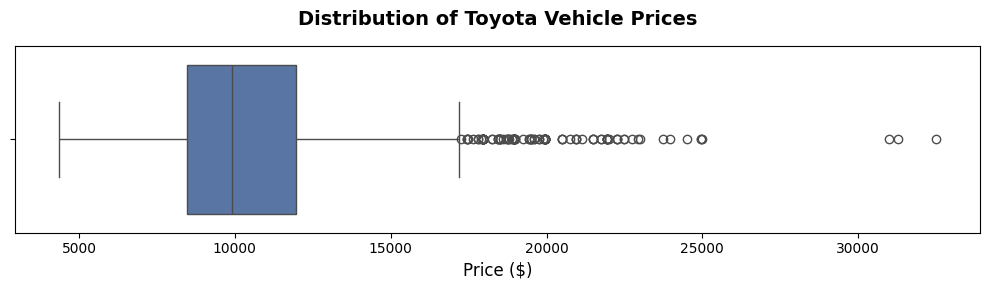

In [7]:
# Create the figure
fig, ax = plt.subplots(figsize=(10, 3))

# Plot the Price column
sns.boxplot(x=toyota["Price"], color="#4c72b0", ax=ax)

# Clean up annotations and presentation
ax.set_title("Distribution of Toyota Vehicle Prices", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Price ($)", fontsize=12)

plt.tight_layout()
plt.savefig("toyota_prices_dist")
plt.show()

In [8]:
# Calculate Q1 (25th percentile) and Q3 (75th percentile)
q1 = toyota['Price'].quantile(0.25)
q3 = toyota['Price'].quantile(0.75)

# Calculate IQR
iqr = q3 - q1

# Define outlier bounds
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# The ~ operator selects rows where the condition evaluates to False (the non-outliers)
toyota_clean = toyota[~((toyota["Price"] < lower_bound) | (toyota["Price"] > upper_bound))]

print(toyota_clean.shape)

(1326, 39)


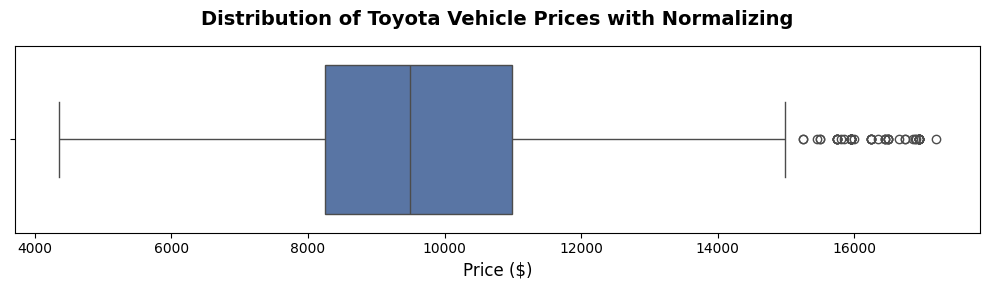

In [9]:
# Create the figure
fig, ax = plt.subplots(figsize=(10, 3))

# Plot the Price column
sns.boxplot(x=toyota_clean["Price"], color="#4c72b0", ax=ax)

# Clean up annotations and presentation
ax.set_title("Distribution of Toyota Vehicle Prices with Normalizing", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Price ($)", fontsize=12)

plt.tight_layout()
plt.savefig("toyota_prices_dist_clean")
plt.show()

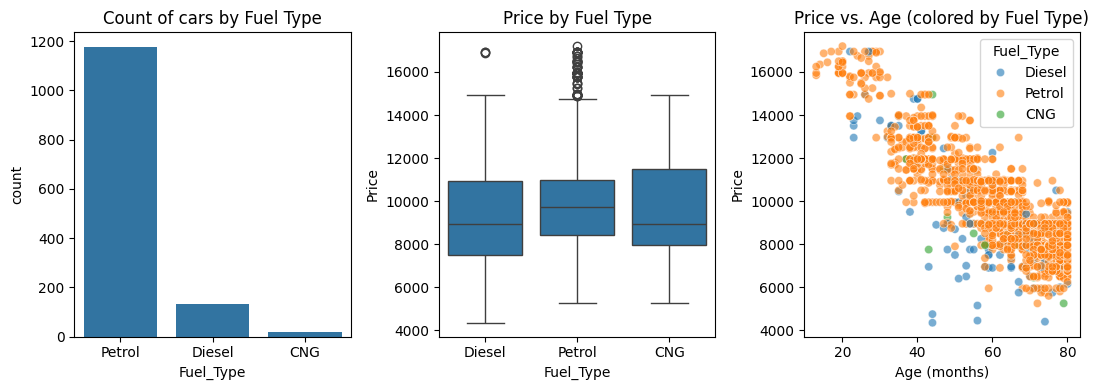

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4))

sns.countplot(data=toyota_clean, x="Fuel_Type", order=toyota["Fuel_Type"].value_counts().index,
              ax=axes[0])
axes[0].set_title("Count of cars by Fuel Type")

sns.boxplot(data=toyota_clean, x="Fuel_Type", y="Price", ax=axes[1])
axes[1].set_title("Price by Fuel Type")

sns.scatterplot(data=toyota_clean, x="Age_08_04", y="Price", hue="Fuel_Type", alpha=0.6, ax=axes[2])
axes[2].set_title("Price vs. Age (colored by Fuel Type)")
axes[2].set_xlabel("Age (months)")

plt.tight_layout()
plt.savefig("fuel_types")
plt.show()

Correlation Matrix:
                          Id     Price  Age_08_04  Mfg_Month  Mfg_Year  \
Id                 1.000000 -0.744913   0.917956   0.031245 -0.941724   
Price             -0.744913  1.000000  -0.843054   0.034542  0.850753   
Age_08_04          0.917956 -0.843054   1.000000  -0.190822 -0.975650   
Mfg_Month          0.031245  0.034542  -0.190822   1.000000 -0.029125   
Mfg_Year          -0.941724  0.850753  -0.975650  -0.029125  1.000000   
KM                 0.154719 -0.520876   0.390216  -0.040131 -0.388385   
HP                 0.002585  0.196581  -0.046749  -0.033921  0.055183   
Met_Color         -0.055131  0.087001  -0.078833   0.034835  0.072491   
Automatic          0.093819  0.019743   0.063534   0.000342 -0.064773   
CC                -0.126667  0.012072  -0.046351   0.066978  0.032233   
Doors             -0.099743  0.153564  -0.095930  -0.006937  0.099234   
Cylinders               NaN       NaN        NaN        NaN       NaN   
Gears             -0.015936  0

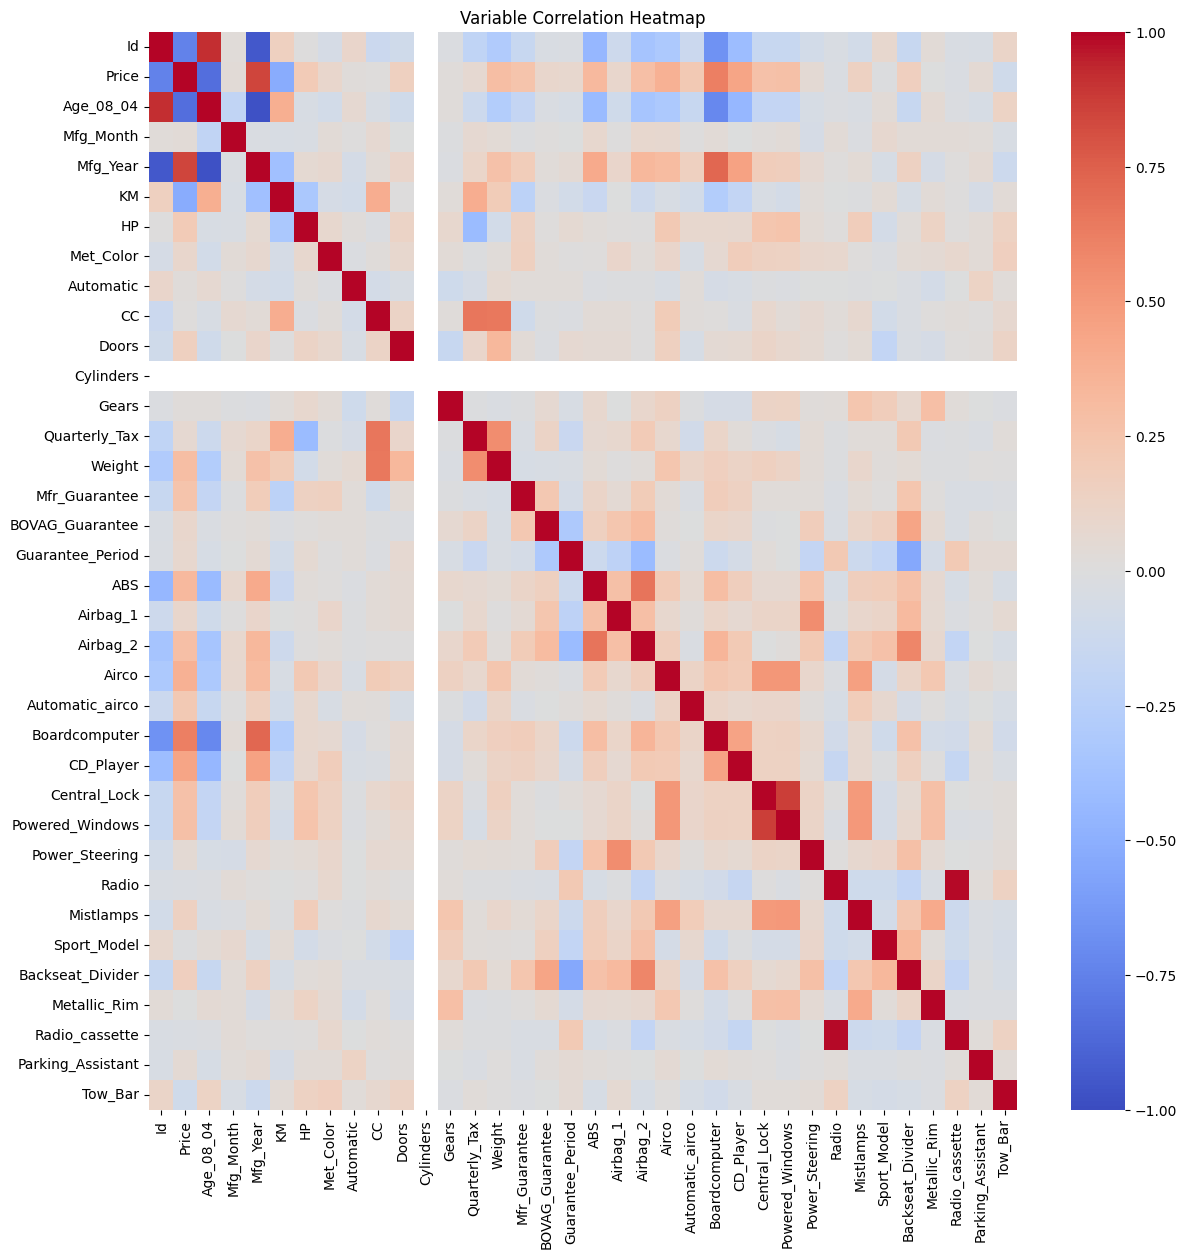

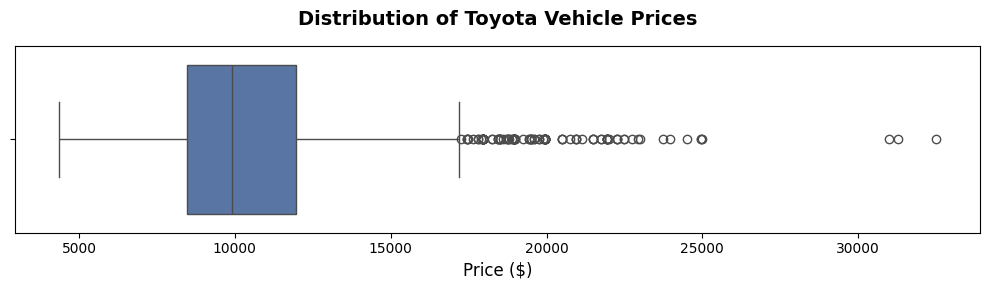

In [11]:
num_cols = toyota_clean.select_dtypes(include="number").columns

#Generate the correlation matrix (Defaults to Pearson)
corr_matrix = toyota_clean[num_cols].corr()
print("Correlation Matrix:\n", corr_matrix)

# 3. Visualize with a Heatmap
plt.figure(figsize=(14,14))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Variable Correlation Heatmap")
# Create the figure
fig, ax = plt.subplots(figsize=(10, 3))

# Plot the Price column
sns.boxplot(x=toyota["Price"], color="#4c72b0", ax=ax)

# Clean up annotations and presentation
ax.set_title("Distribution of Toyota Vehicle Prices", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Price ($)", fontsize=12)

plt.tight_layout()
plt.savefig("toyota_matrix")
plt.show()
plt.show()

We see that there is a strong negative correlation between Price and Age_08_04 which the age of the vehicle in months counting backwards
from August 2004.

In [12]:
months = toyota_clean["Age_08_04"].unique()
print(months)
print(toyota_clean['Age_08_04'].describe())
print("How old a car is in months counting back from August 2004: ", 80-13)

[23 24 26 30 32 27 29 28 25 22 19 20 14 17 13 16 15 43 38 40 44 41 37 39
 42 35 34 33 36 53 51 54 45 55 48 52 49 56 50 47 46 58 68 59 62 65 67 64
 60 61 66 57 63 73 79 78 74 77 69 80 76 70 71 75 72]
count    1326.000000
mean       59.159879
std        15.278351
min        13.000000
25%        49.250000
50%        62.000000
75%        71.000000
max        80.000000
Name: Age_08_04, dtype: float64
How old a car is in months counting back from August 2004:  67


In [13]:
# Set the baseline date (August 2004)
base_date = datetime(2004, 8, 1)

# Subtract exactly 67 months
target_date = base_date - relativedelta(months=67)

# Print the result in a readable format
print("Start date of Corolla Manufacturing: ", target_date.strftime("%B %Y"))

Start date of Corolla Manufacturing:  January 1999


### 1.2 Get Dummies

In [14]:
toyota_d = pd.get_dummies(toyota_clean, columns=["Fuel_Type"], dtype=int)
toyota_d = toyota_d.rename(columns={"Fuel_Type_Petrol": "Petrol",
                                    "Fuel_Type_Diesel": "Diesel",
                                    "Fuel_Type_CNG": "CNG"})

# Dummies are mutually exclusive and exhaustive: every row has exactly one fuel type
print("Row-wise sum of dummies equals 1 for all rows:",
      bool((toyota_d[["Petrol", "Diesel", "CNG"]].sum(axis=1) == 1).all()))

Row-wise sum of dummies equals 1 for all rows: True


In [15]:
toyota_d

,Id,Model,Price,Age_08_04,Mfg_Month,Mfg_Year,KM,HP,Met_Color,Color,...,Mistlamps,Sport_Model,Backseat_Divider,Metallic_Rim,Radio_cassette,Parking_Assistant,Tow_Bar,CNG,Diesel,Petrol
0,1,TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors,13500,23,10,2002,46986,90,1,Blue,...,0,0,1,0,0,0,0,0,1,0
1,2,TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors,13750,23,10,2002,72937,90,1,Silver,...,0,0,1,0,0,0,0,0,1,0
2,3,TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors,13950,24,9,2002,41711,90,1,Blue,...,0,0,1,0,0,0,0,0,1,0
3,4,TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors,14950,26,7,2002,48000,90,0,Black,...,0,0,1,0,0,0,0,0,1,0
4,5,TOYOTA Corolla 2.0 D4D HATCHB SOL 2/3-Doors,13750,30,3,2002,38500,90,0,Black,...,1,0,1,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1431,1438,TOYOTA Corolla 1.3 16V HATCHB G6 2/3-Doors,7500,69,12,1998,20544,86,1,Blue,...,1,1,1,0,0,0,0,0,0,1
1432,1439,TOYOTA Corolla 1.3 16V HATCHB LINEA TERRA 2/3-...,10845,72,9,1998,19000,86,0,Grey,...,0,1,1,0,0,0,0,0,0,1
1433,1440,TOYOTA Corolla 1.3 16V HATCHB LINEA TERRA 2/3-...,8500,71,10,1998,17016,86,0,Blue,...,0,0,1,0,0,0,0,0,0,1
1434,1441,TOYOTA Corolla 1.3 16V HATCHB LINEA TERRA 2/3-...,7250,70,11,1998,16916,86,1,Grey,...,0,0,1,0,0,0,0,0,0,1


In [16]:
train_df, valid_df = train_test_split(toyota_d, test_size=0.4, random_state=42)
print(f"Training rows: {len(train_df)}   Validation rows: {len(valid_df)}")

Training rows: 795   Validation rows: 531


### 1.3 Fit Model 1 (Petrol, Diesel) and Model 2 (Petrol, CNG)

In [17]:
def fit_ols(df, predictors, target="Price"):
    X = sm.add_constant(df[predictors].astype(float))
    return sm.OLS(df[target].astype(float), X).fit()

M1_cols = ["Age_08_04", "Petrol", "Diesel"]
M2_cols = ["Age_08_04", "Petrol", "CNG"]

model1 = fit_ols(train_df, M1_cols)
model2 = fit_ols(train_df, M2_cols)

print("=" * 30, "MODEL 1 (Petrol, Diesel)", "=" * 30)
print(model1.summary())
print("\n" + "=" * 30, "MODEL 2 (Petrol, CNG)", "=" * 30)
print(model2.summary())

============================== MODEL 1 (Petrol, Diesel) ==============================
                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.734
Model:                            OLS   Adj. R-squared:                  0.733
Method:                 Least Squares   F-statistic:                     728.7
Date:                Tue, 24 Nov 2026   Prob (F-statistic):          4.30e-227
Time:                        17:26:34   Log-Likelihood:                -6787.1
No. Observations:                 795   AIC:                         1.358e+04
Df Residuals:                     791   BIC:                         1.360e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------

### 1.4 Compare fit statistics

In [18]:
def fit_stats(m):
    return {
        "R-squared": m.rsquared,
        "Adjusted R-squared": m.rsquared_adj,
        "F-statistic": m.fvalue,
        "Prob (F-statistic)": m.f_pvalue,
        "Residual standard error": np.sqrt(m.mse_resid),
        "AIC": m.aic,
        "BIC": m.bic,
        "Log-likelihood": m.llf,
    }

stats_table = pd.DataFrame({"Model 1 (Petrol, Diesel)": fit_stats(model1),
                            "Model 2 (Petrol, CNG)": fit_stats(model2)})

stats_table["Absolute difference"] = (stats_table.iloc[:, 0] - stats_table.iloc[:, 1]).abs().round(10)
stats_table

,"Model 1 (Petrol, Diesel)","Model 2 (Petrol, CNG)",Absolute difference
R-squared,7.342967e-01,7.342967e-01,0.0
Adjusted R-squared,7.332890e-01,7.332890e-01,0.0
F-statistic,7.286682e+02,7.286682e+02,0.0
Prob (F-statistic),4.301037e-227,4.301037e-227,0.0
Residual standard error,1.237389e+03,1.237389e+03,0.0
AIC,1.358211e+04,1.358211e+04,0.0
BIC,1.360082e+04,1.360082e+04,0.0
Log-likelihood,-6.787054e+03,-6.787054e+03,0.0


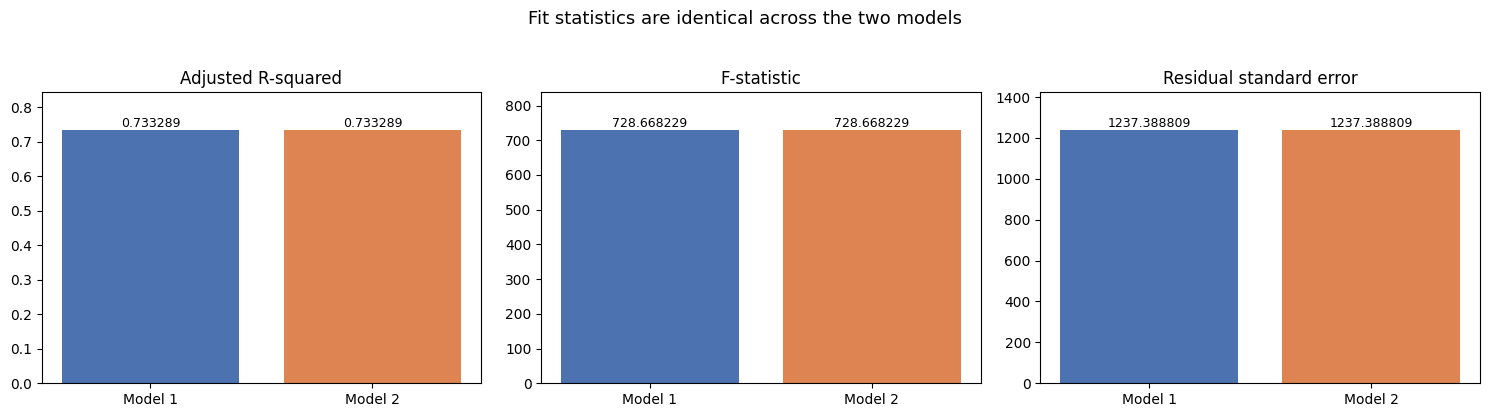

In [19]:
# Visual comparison of the statistics: the bars should be identical in each pair
stats_plot = stats_table.iloc[:, :2].T
stats_plot = stats_plot[["Adjusted R-squared", "F-statistic", "Residual standard error"]]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, stats_plot.columns):
    vals = stats_plot[col]
    ax.bar(["Model 1", "Model 2"], vals, color=["#4C72B0", "#DD8452"])
    ax.set_title(col)
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.6f}", ha="center", va="bottom", fontsize=9)
    ax.set_ylim(0, vals.max() * 1.15)
plt.suptitle("Fit statistics are identical across the two models", y=1.03, fontsize=13)
plt.tight_layout()
plt.savefig("toyota_stats")
plt.show()

### 1.5 Coefficients differ: the same fit with a different reference category

In [20]:
coef_table = pd.DataFrame({
    "Model 1 coef": model1.params,
    "Model 2 coef": model2.params,
}).reindex(["const", "Age_08_04", "Petrol", "Diesel", "CNG"])
coef_table

,Model 1 coef,Model 2 coef
const,17052.461160,16782.028170
Age_08_04,-132.091688,-132.091688
Petrol,868.477786,1138.910777
Diesel,-270.432991,NaN
CNG,NaN,270.432991


### 1.6 Predictions and residuals on the validation set

In [21]:
pred1 = model1.predict(sm.add_constant(valid_df[M1_cols].astype(float)))
pred2 = model2.predict(sm.add_constant(valid_df[M2_cols].astype(float)))

results = pd.DataFrame({
    "Actual Price": valid_df["Price"],
    "Pred Model 1": pred1,
    "Pred Model 2": pred2,
    "Residual Model 1": valid_df["Price"] - pred1,
    "Residual Model 2": valid_df["Price"] - pred2,
})
print("Head of validation results:")
results.head(5)

Head of validation results:


,Actual Price,Pred Model 1,Pred Model 2,Residual Model 1,Residual Model 2
999,10950,10391.712748,10391.712748,558.287252,558.287252
577,11950,10523.804436,10523.804436,1426.195564,1426.195564
997,9950,9599.162622,9599.162622,350.837378,350.837378
284,11950,12505.179751,12505.179751,-555.179751,-555.179751
1396,9800,7749.878995,7749.878995,2050.121005,2050.121005


In [22]:
print("Max |difference| in predictions:", round(np.max(np.abs(pred1 - pred2)), 10))
print("Max |difference| in residuals  :", round(np.max(np.abs(results["Residual Model 1"] - results["Residual Model 2"])), 10))
if np.allclose(results["Pred Model 1"], results["Pred Model 2"], equal_nan=True):
    print("Model 1 has the same predictions as Model 2")
else:
    print("Model 1 does not have the same predictions as Model 2")

if np.allclose(
    results["Residual Model 1"], results["Residual Model 2"], equal_nan=True
):
    print("Residuals of Model 1 are the same as Residuals of Model 2")
else:
    print("Residuals of Model 1 are not the same as Residuals of Model 2")

Max |difference| in predictions: 0.0
Max |difference| in residuals  : 0.0
Model 1 has the same predictions as Model 2
Residuals of Model 1 are the same as Residuals of Model 2


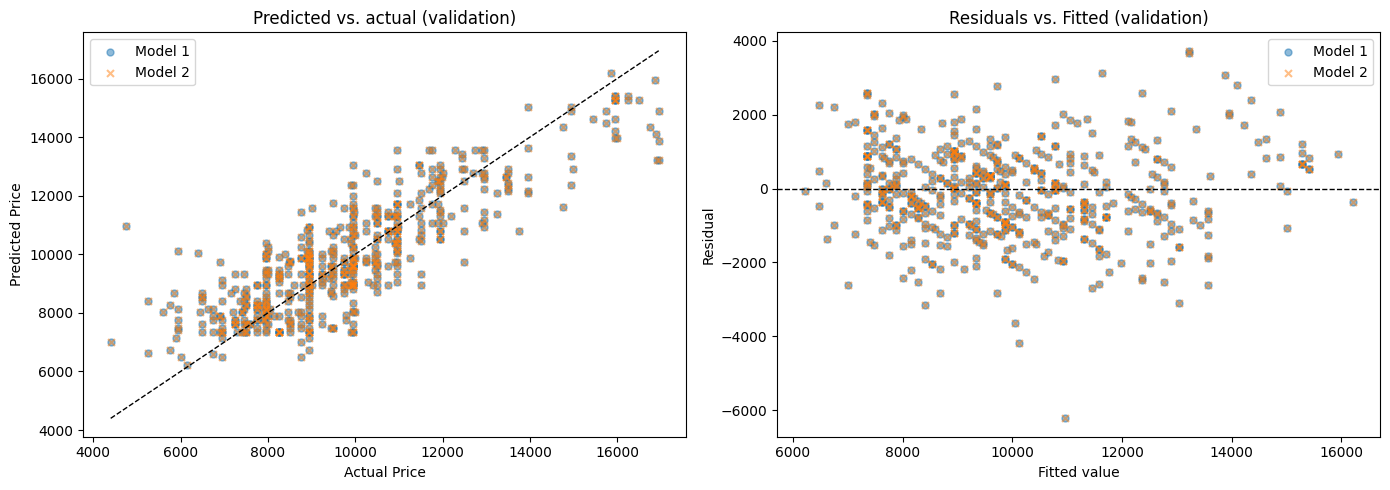

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Predicted vs actual: the two models overlap exactly
axes[0].scatter(valid_df["Price"], pred1, alpha=0.5, s=25, label="Model 1")
axes[0].scatter(valid_df["Price"], pred2, alpha=0.5, s=25, marker="x", label="Model 2")
lims = [valid_df["Price"].min(), valid_df["Price"].max()]
axes[0].plot(lims, lims, "k--", lw=1)
axes[0].set_title("Predicted vs. actual (validation)")
axes[0].set_xlabel("Actual Price"); axes[0].set_ylabel("Predicted Price")
axes[0].legend()

# Residuals vs fitted
axes[1].scatter(pred1, results["Residual Model 1"], alpha=0.5, s=25, label="Model 1")
axes[1].scatter(pred2, results["Residual Model 2"], alpha=0.5, s=25, marker="x", label="Model 2")
axes[1].axhline(0, color="k", ls="--", lw=1)
axes[1].set_title("Residuals vs. Fitted (validation)")
axes[1].set_xlabel("Fitted value"); axes[1].set_ylabel("Residual")
axes[1].legend()

plt.tight_layout()
plt.savefig("toyota_residuals")
plt.show()
axes[1].legend()


## 2. Universal Bank Dataset

### 2.a

In [24]:
bank = pd.read_csv("UniversalBank.csv")

In [25]:
bank.head()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [26]:
bank = bank.rename(columns={'Personal Loan': 'Personal_Loan'})
bank.drop(columns=['ID'], inplace=True)

In [27]:
bank.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5000 non-null   int64  
 1   Experience          5000 non-null   int64  
 2   Income              5000 non-null   int64  
 3   ZIP Code            5000 non-null   int64  
 4   Family              5000 non-null   int64  
 5   CCAvg               5000 non-null   float64
 6   Education           5000 non-null   int64  
 7   Mortgage            5000 non-null   int64  
 8   Personal_Loan       5000 non-null   int64  
 9   Securities Account  5000 non-null   int64  
 10  CD Account          5000 non-null   int64  
 11  Online              5000 non-null   int64  
 12  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(12)
memory usage: 507.9 KB


In [28]:
binary_columns = [col for col in bank.columns if bank[col].isin([0, 1]).all()]

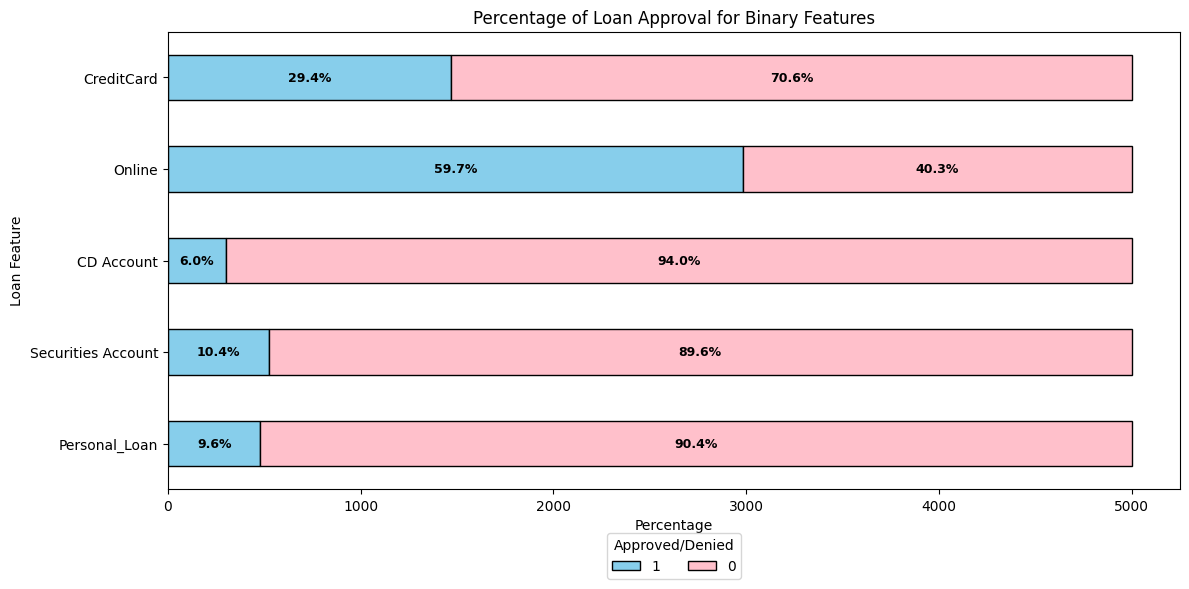

In [29]:
binary_df_cols = [col for col in bank.columns if col in binary_columns]

# Calculate counts of 0 and 1 for each of these columns using the correct 'bank' DataFrame
binary_counts = pd.DataFrame({
    '1': [bank[col].value_counts().get(1, 0) for col in binary_df_cols],
    '0': [bank[col].value_counts().get(0, 0) for col in binary_df_cols]
}, index=binary_df_cols)

# Calculate row-wise percentages
binary_pcts = binary_counts.div(binary_counts.sum(axis=1), axis=0) * 100

# Plot a stacked horizontal bar chart
plt.figure(figsize=(12, 6))
ax = plt.gca()
binary_counts.plot(kind='barh', stacked=True, color=['skyblue', 'pink'], edgecolor='black', ax=ax)

# Annotate the percentages onto each bar segment
for i, container in enumerate(ax.containers):
    # Get category name ('1' or '0')
    col_name = '1' if i == 0 else '0'

    for j, patch in enumerate(container.get_children()):
        width = patch.get_width()
        if width > 0:  # Only annotate bars with non-zero width
            # Retrieve the corresponding percentage
            pct_val = binary_pcts.iloc[j][col_name]
            x_pos = patch.get_x() + width / 2
            y_pos = patch.get_y() + patch.get_height() / 2
            ax.text(x_pos, y_pos, f'{pct_val:.1f}%',
                    ha='center', va='center', fontsize=9, fontweight='bold', color='black')

plt.title('Percentage of Loan Approval for Binary Features')
plt.xlabel('Percentage')
plt.ylabel('Loan Feature')

plt.legend(title='Approved/Denied', loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2)

plt.tight_layout()
plt.savefig("Binary Variables.png")
plt.show()

Why did the mortgage column not show up on my Binary Features Chart?

In [30]:
bank["Mortgage"].unique()

array([  0, 155, 104, 134, 111, 260, 163, 159,  97, 122, 193, 198, 285,
       412, 153, 211, 207, 240, 455, 112, 336, 132, 118, 174, 126, 236,
       166, 136, 309, 103, 366, 101, 251, 276, 161, 149, 188, 116, 135,
       244, 164,  81, 315, 140,  95,  89,  90, 105, 100, 282, 209, 249,
        91,  98, 145, 150, 169, 280,  99,  78, 264, 113, 117, 325, 121,
       138,  77, 158, 109, 131, 391,  88, 129, 196, 617, 123, 167, 190,
       248,  82, 402, 360, 392, 185, 419, 270, 148, 466, 175, 147, 220,
       133, 182, 290, 125, 124, 224, 141, 119, 139, 115, 458, 172, 156,
       547, 470, 304, 221, 108, 179, 271, 378, 176,  76, 314,  87, 203,
       180, 230, 137, 152, 485, 300, 272, 144,  94, 208, 275,  83, 218,
       327, 322, 205, 227, 239,  85, 160, 364, 449,  75, 107,  92, 187,
       355, 106, 587, 214, 307, 263, 310, 127, 252, 170, 265, 177, 305,
       372,  79, 301, 232, 289, 212, 250,  84, 130, 303, 256, 259, 204,
       524, 157, 231, 287, 247, 333, 229, 357, 361, 294,  86, 32

In [31]:
bank["Experience"].unique()

array([ 1, 19, 15,  9,  8, 13, 27, 24, 10, 39,  5, 23, 32, 41, 30, 14, 18,
       21, 28, 31, 11, 16, 20, 35,  6, 25,  7, 12, 26, 37, 17,  2, 36, 29,
        3, 22, -1, 34,  0, 38, 40, 33,  4, -2, 42, -3, 43])

In [32]:
bank = bank[bank["Experience"] >= 0]

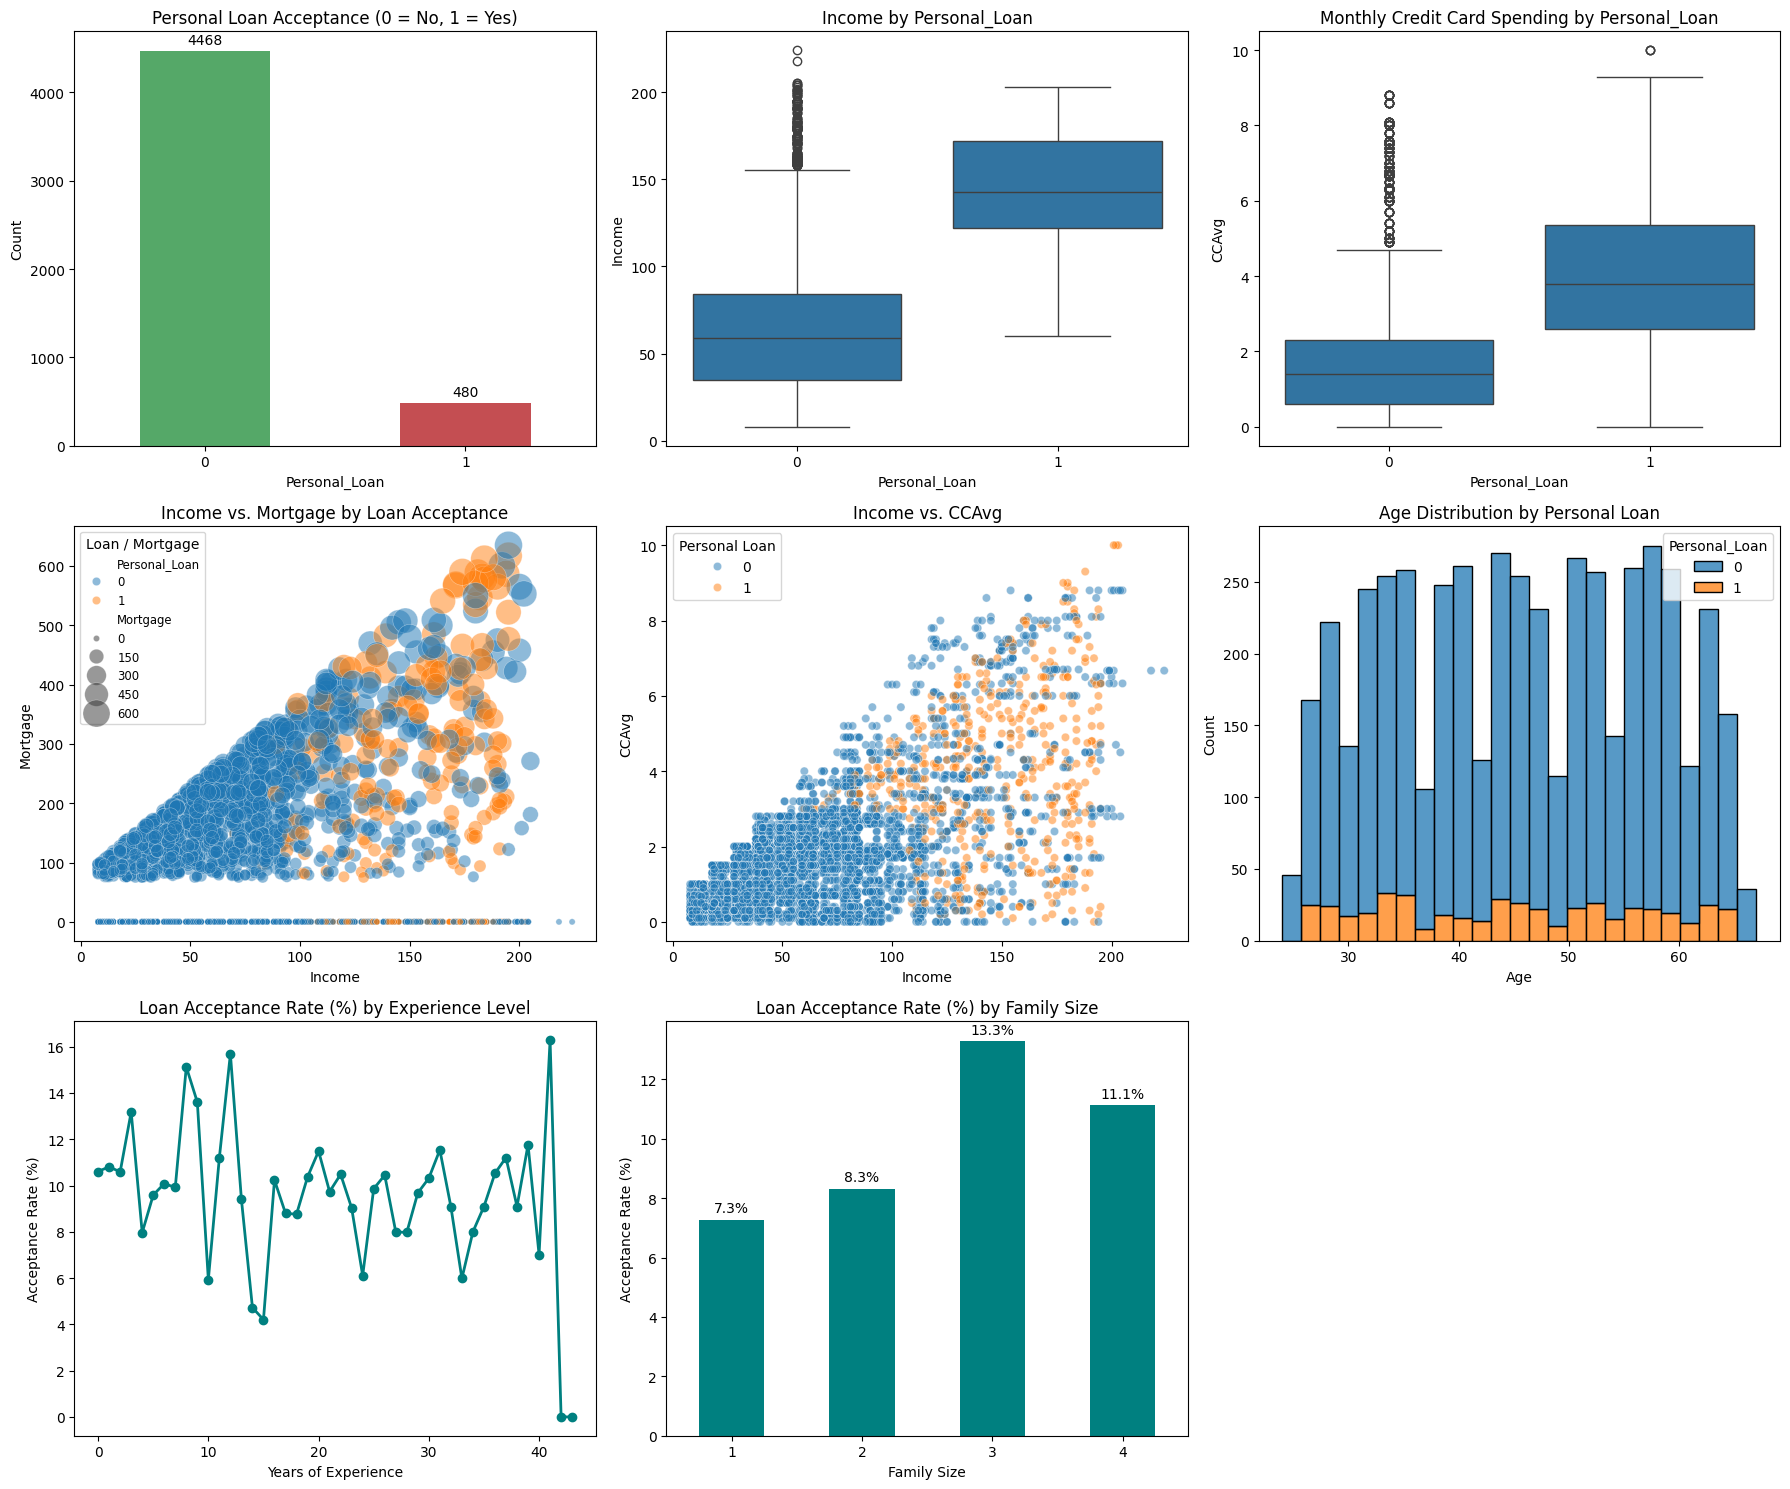

In [33]:
fig, axes = plt.subplots(3, 3, figsize=(18, 15))

# --- ROW 0 ---
# Plot 1: Personal Loan Acceptance Level (Row 0, Col 0)
bank["Personal_Loan"].value_counts().plot.bar(
    ax=axes[0, 0], color=["#55A868", "#C44E52"], rot=0
)
axes[0, 0].set_title("Personal Loan Acceptance (0 = No, 1 = Yes)")
axes[0, 0].set_xlabel("Personal_Loan")
axes[0, 0].set_ylabel("Count")
axes[0, 0].bar_label(axes[0, 0].containers[0], padding=3)

# Plot 2: Income by Personal Loan (Row 0, Col 1)
sns.boxplot(data=bank, x="Personal_Loan", y="Income", ax=axes[0, 1])
axes[0, 1].set_title("Income by Personal_Loan")

# Plot 3: Monthly Credit Card Spending by Personal Loan (Row 0, Col 2)
sns.boxplot(data=bank, x="Personal_Loan", y="CCAvg", ax=axes[0, 2])
axes[0, 2].set_title("Monthly Credit Card Spending by Personal_Loan")

# --- ROW 1 ---
# Plot 4: Income vs. Mortgage Bubble Chart (Row 1, Col 0)
sns.scatterplot(
    data=bank,
    x="Income",
    y="Mortgage",
    hue="Personal_Loan",
    size="Mortgage",
    sizes=(20, 400),
    alpha=0.5,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Income vs. Mortgage by Loan Acceptance")
axes[1, 0].legend(title="Loan / Mortgage", loc="upper left", fontsize="small")

# Plot 5: Income vs. CCAvg (Row 1, Col 1)
sns.scatterplot(
    data=bank,
    x="Income",
    y="CCAvg",
    hue="Personal_Loan",
    alpha=0.5,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Income vs. CCAvg")
axes[1, 1].legend(title="Personal Loan")

# Plot 6: Age Distribution (Row 1, Col 2)
sns.histplot(
    data=bank,
    x="Age",
    hue="Personal_Loan",
    multiple="stack",
    bins=25,
    ax=axes[1, 2]
)
axes[1, 2].set_title("Age Distribution by Personal Loan")

# Plot 7: Experience Level Acceptance Rate (Row 2, Col 0)
# Calculate experience level acceptance rate percentages
exp_rate = bank.groupby("Experience")["Personal_Loan"].mean().mul(100)
exp_x = exp_rate.index
exp_y = exp_rate.values

axes[2, 0].plot(exp_x, exp_y, color="teal", marker="o", linewidth=2, linestyle="-")
axes[2, 0].set_title("Loan Acceptance Rate (%) by Experience Level")
axes[2, 0].set_xlabel("Years of Experience")
axes[2, 0].set_ylabel("Acceptance Rate (%)")

# Plot 8: Family Size Acceptance Rate (Row 2, Col 1)
fam_rate = bank.groupby("Family")["Personal_Loan"].mean().mul(100)
fam_rate.plot.bar(ax=axes[2, 1], color="teal", rot=0)
axes[2, 1].set_title("Loan Acceptance Rate (%) by Family Size")
axes[2, 1].set_xlabel("Family Size")
axes[2, 1].set_ylabel("Acceptance Rate (%)")
axes[2, 1].bar_label(axes[2, 1].containers[0], fmt="%.1f%%", padding=3)

axes[2, 2].set_visible(False)

plt.savefig("Universal Bank.png")
plt.tight_layout()
plt.show()

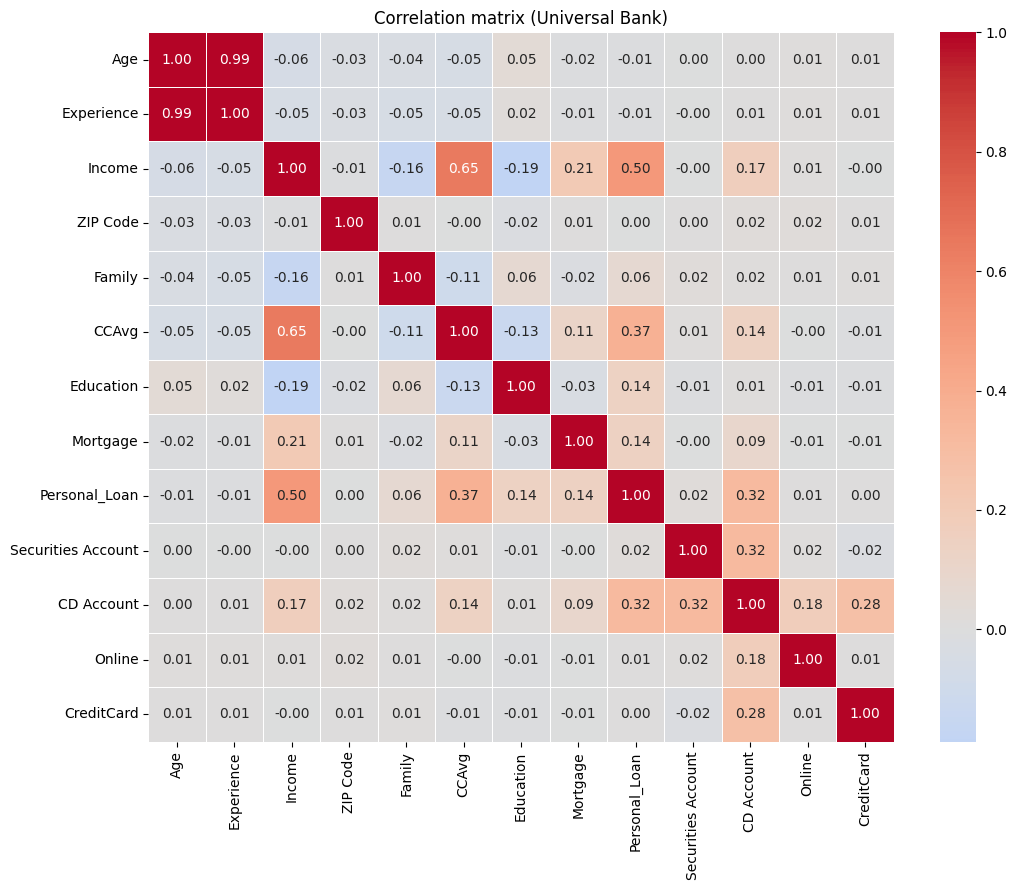

<Figure size 640x480 with 0 Axes>

In [34]:
plt.figure(figsize=(11, 9))
sns.heatmap(bank.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, linewidths=0.4)
plt.title("Correlation matrix (Universal Bank)")
plt.tight_layout()
plt.show()

plt.savefig("Universal Bank matrix.png")

In [35]:
bank.columns

Index(['Age', 'Experience', 'Income', 'ZIP Code', 'Family', 'CCAvg',
       'Education', 'Mortgage', 'Personal_Loan', 'Securities Account',
       'CD Account', 'Online', 'CreditCard'],
      dtype='object')

In [36]:
# Remove the missing 'ZIP_clean' column from the list of predictors
predictors = ['Age', 'Experience', 'Income', 'ZIP Code', 'Family', 'CCAvg',
              'Education', 'Mortgage', 'Personal_Loan', 'Securities Account',
              'CD Account', 'Online', 'CreditCard']

x = bank[predictors]
y = bank['Personal_Loan']

In [37]:
X = bank.drop(columns=["Personal_Loan"])
y = bank["Personal_Loan"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.4, random_state=42)

print("Feature columns:", list(X.columns))
print(f"Train: {X_train.shape}   Validation: {X_valid.shape}")
print(f"Majority-class baseline accuracy on validation: {y_valid.value_counts(normalize=True).max():.4f}")

Feature columns: ['Age', 'Experience', 'Income', 'ZIP Code', 'Family', 'CCAvg', 'Education', 'Mortgage', 'Securities Account', 'CD Account', 'Online', 'CreditCard']
Train: (2968, 12)   Validation: (1980, 12)
Majority-class baseline accuracy on validation: 0.9076


In [38]:
X_train.head()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Securities Account,CD Account,Online,CreditCard
322,63,39,101,92007,1,3.9,1,0,1,1,1,0
3229,33,9,64,92507,4,3.4,1,0,0,0,0,0
2861,42,18,60,92677,4,0.2,3,151,0,0,0,1
4052,43,19,54,94608,2,1.7,1,0,0,0,1,0
3141,57,31,131,90405,3,0.6,1,0,0,0,1,0


In [39]:
raw_customer = pd.DataFrame([{
    "Age": 40,
    "Experience": 10,
    "Income": 84,
    "ZIP Code": 92007,
    "Family": 2,
    "CCAvg": 2.0,
    "Education": 2,
    "Mortgage": 0,
    "Securities Account": 0,
    "CD Account": 0,
    "Online": 1,
    "CreditCard": 1
}])

# Specify the exact columns that were one-hot encoded during training
new_customer = pd.get_dummies(raw_customer, columns=["Education", "Family"]).reindex(
    columns=X.columns, fill_value=0
)

knn3 = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3))
knn3.fit(X_train, y_train)

pred_new = knn3.predict(new_customer)[0]
proba_new = knn3.predict_proba(new_customer)[0]
print(f"Predicted Personal_Loan for new customer (k=3): {pred_new}")
print(f"Class probabilities  P(no loan)={proba_new[0]:.3f}   P(loan)={proba_new[1]:.3f}")

Predicted Personal_Loan for new customer (k=3): 0
Class probabilities  P(no loan)=1.000   P(loan)=0.000


In [40]:
# Which 3 training customers are the nearest neighbors?
scaler_fit = knn3.named_steps["standardscaler"]
knn_fit = knn3.named_steps["kneighborsclassifier"]
dist, idx = knn_fit.kneighbors(scaler_fit.transform(new_customer))

neighbors = X_train.iloc[idx[0]].copy()
neighbors["Personal_Loan"] = y_train.iloc[idx[0]].values
neighbors["Distance"] = dist[0]
neighbors

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Securities Account,CD Account,Online,CreditCard,Personal_Loan,Distance
3915,38,13,91,92037,1,2.8,1,0,0,0,1,1,0,1.579435
1127,35,9,58,91101,1,2.5,1,0,0,0,1,1,0,1.735344
4807,40,14,53,90064,1,2.0,1,0,0,0,1,1,0,1.978295


In [41]:
# Scale the features first to define X_train_scaled and X_valid_scaled
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

# find the optimal value of k using a for loop
train_accuracy = []
valid_accuracy = []

k_values = range(1, 21)

for k in k_values:

    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train_scaled, y_train)

    train_pred = knn.predict(X_train_scaled)
    valid_pred = knn.predict(X_valid_scaled)

    train_accuracy.append(
        accuracy_score(y_train, train_pred)
    )

    valid_accuracy.append(
        accuracy_score(y_valid, valid_pred)
    )

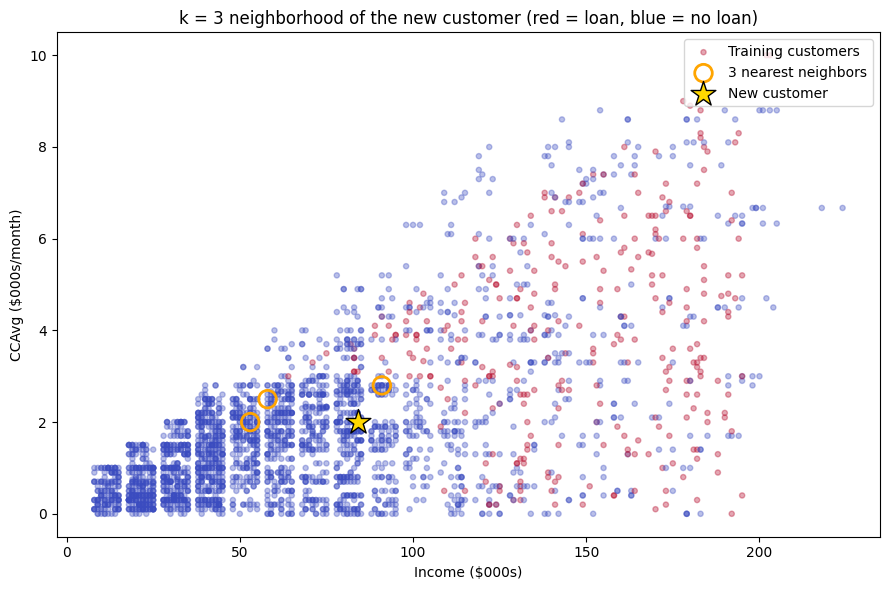

In [42]:
# Visualize the new customer and its 3 nearest neighbors in Income x CCAvg space
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(X_train["Income"], X_train["CCAvg"], c=y_train, cmap="coolwarm",
           s=14, alpha=0.35, label="Training customers")
ax.scatter(neighbors["Income"], neighbors["CCAvg"], s=160, facecolors="none",
           edgecolors="orange", linewidths=2, label="3 nearest neighbors")
ax.scatter(new_customer["Income"], new_customer["CCAvg"], marker="*", s=350,
           color="gold", edgecolors="black", label="New customer")
ax.set_xlabel("Income ($000s)"); ax.set_ylabel("CCAvg ($000s/month)")
ax.set_title("k = 3 neighborhood of the new customer (red = loan, blue = no loan)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("New Customer.png")
plt.show()

### 2 (b)

In [43]:
ks = list(range(1, 20))
records = []
for k in ks:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    model.fit(X_train, y_train)
    records.append({
        "k": k,
        "Train accuracy": model.score(X_train, y_train),
        "Validation accuracy": model.score(X_valid, y_valid),
    })
k_results = pd.DataFrame(records)
k_results["Gap (train - valid)"] = k_results["Train accuracy"] - k_results["Validation accuracy"]

best_k = int(k_results.loc[k_results["Validation accuracy"].idxmax(), "k"])
print(f"Best k on validation set: {best_k}")
print(f"Validation accuracy at best k: {k_results.loc[k_results.k == best_k, 'Validation accuracy'].item():.4f}")
k_results.head(10)

Best k on validation set: 3
Validation accuracy at best k: 0.9540


,k,Train accuracy,Validation accuracy,Gap (train - valid)
0,1,1.000000,0.950505,0.049495
1,2,0.962938,0.942424,0.020514
2,3,0.972709,0.954040,0.018668
3,4,0.958558,0.947475,0.011083
4,5,0.965296,0.953030,0.012266
5,6,0.951819,0.951010,0.000809
6,7,0.957547,0.951515,0.006032
7,8,0.947439,0.947980,-0.000540
8,9,0.950809,0.948485,0.002324
9,10,0.944744,0.944444,0.000299


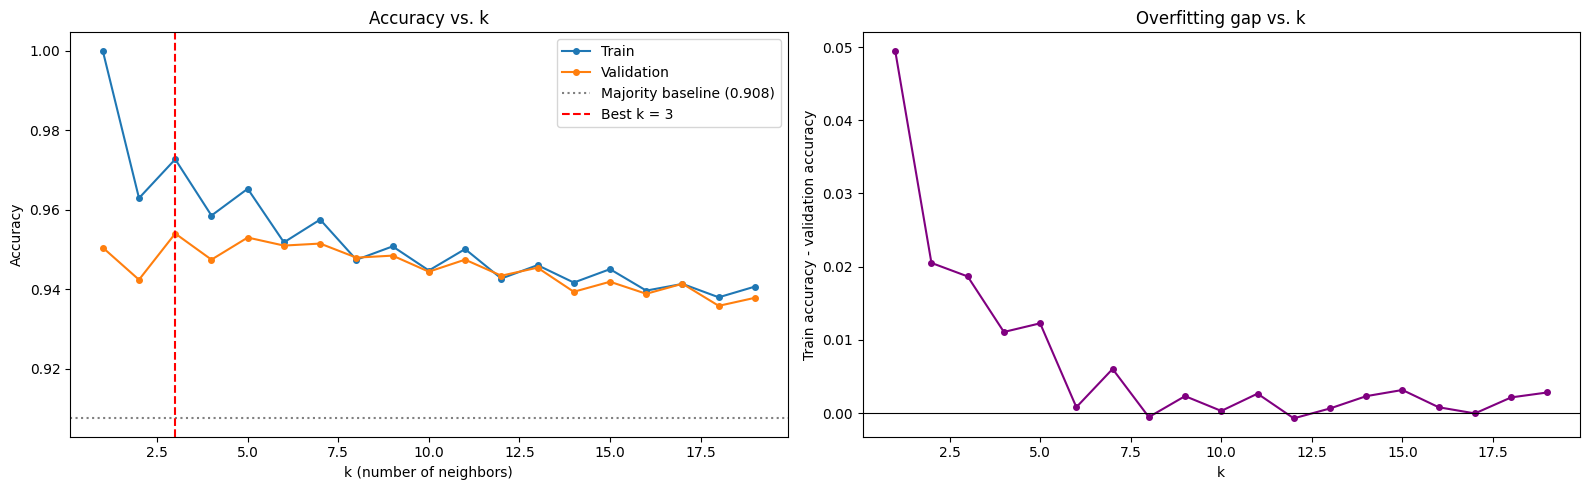

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(k_results["k"], k_results["Train accuracy"], marker="o", ms=4, label="Train")
axes[0].plot(k_results["k"], k_results["Validation accuracy"], marker="o", ms=4, label="Validation")
baseline = y_valid.value_counts(normalize=True).max()
axes[0].axhline(baseline, color="gray", ls=":", label=f"Majority baseline ({baseline:.3f})")
axes[0].axvline(best_k, color="red", ls="--", label=f"Best k = {best_k}")
axes[0].set_xlabel("k (number of neighbors)"); axes[0].set_ylabel("Accuracy")
axes[0].set_title("Accuracy vs. k")
axes[0].legend()

axes[1].plot(k_results["k"], k_results["Gap (train - valid)"], marker="o", ms=4, color="purple")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("k"); axes[1].set_ylabel("Train accuracy - validation accuracy")
axes[1].set_title("Overfitting gap vs. k")

plt.tight_layout()
plt.savefig("Universal Bank KNN.png")
plt.show()

## 3. eBay Auctions Dataset

In [45]:
ebay = pd.read_csv("eBayAuctions.csv")

In [46]:
ebay.head()

,Category,currency,sellerRating,Duration,endDay,ClosePrice,OpenPrice,Competitive?
0,Music/Movie/Game,US,3249,5,Mon,0.01,0.01,0
1,Music/Movie/Game,US,3249,5,Mon,0.01,0.01,0
2,Music/Movie/Game,US,3249,5,Mon,0.01,0.01,0
3,Music/Movie/Game,US,3249,5,Mon,0.01,0.01,0
4,Music/Movie/Game,US,3249,5,Mon,0.01,0.01,0


In [47]:
ebay.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1972 entries, 0 to 1971
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Category      1972 non-null   object 
 1   currency      1972 non-null   object 
 2   sellerRating  1972 non-null   int64  
 3   Duration      1972 non-null   int64  
 4   endDay        1972 non-null   object 
 5   ClosePrice    1972 non-null   float64
 6   OpenPrice     1972 non-null   float64
 7   Competitive?  1972 non-null   int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 123.4+ KB


In [48]:
print(ebay.isnull().sum())
print(ebay.dtypes)

Category        0
currency        0
sellerRating    0
Duration        0
endDay          0
ClosePrice      0
OpenPrice       0
Competitive?    0
dtype: int64
Category         object
currency         object
sellerRating      int64
Duration          int64
endDay           object
ClosePrice      float64
OpenPrice       float64
Competitive?      int64
dtype: object


In [49]:
ebay["Category"].unique()

array(['Music/Movie/Game', 'Automotive', 'SportingGoods', 'Home/Garden',
       'Books', 'Collectibles', 'Business/Industrial', 'Toys/Hobbies',
       'Electronics', 'Computer', 'EverythingElse',
       'Clothing/Accessories', 'Coins/Stamps', 'Antique/Art/Craft',
       'Jewelry', 'Pottery/Glass', 'Health/Beauty', 'Photography'],
      dtype=object)

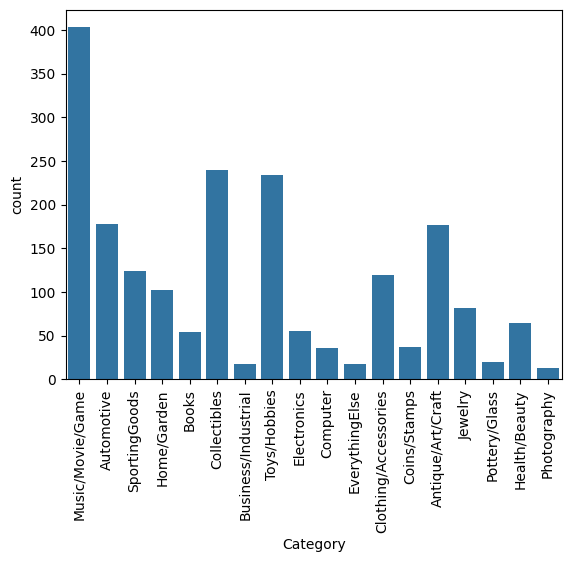

In [50]:
sns.countplot(data=ebay, x="Category")
plt.xticks(rotation=90)
plt.savefig("eBay Category.png")
plt.show()


In [51]:
ebay["currency"].unique()

array(['US', 'GBP', 'EUR'], dtype=object)

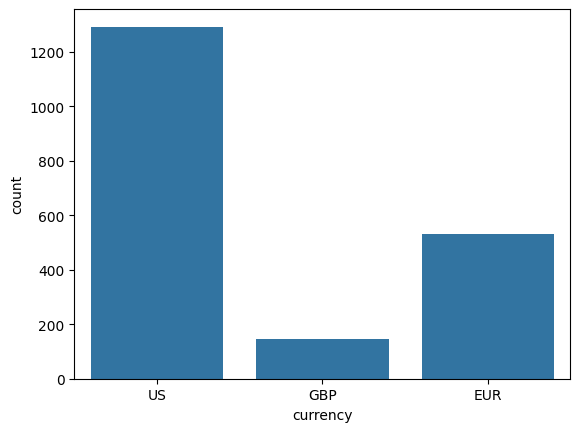

In [52]:
sns.countplot(data=ebay, x="currency")
plt.savefig("eBay Currency.png")
plt.show()

In [53]:
ebay["Duration"].unique()

array([ 5,  7,  1,  3, 10])

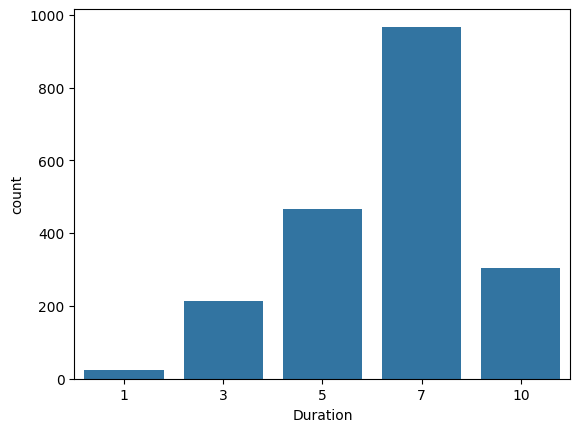

In [54]:
sns.countplot(data=ebay, x="Duration")
plt.savefig("eBay Duration.png")
plt.show()

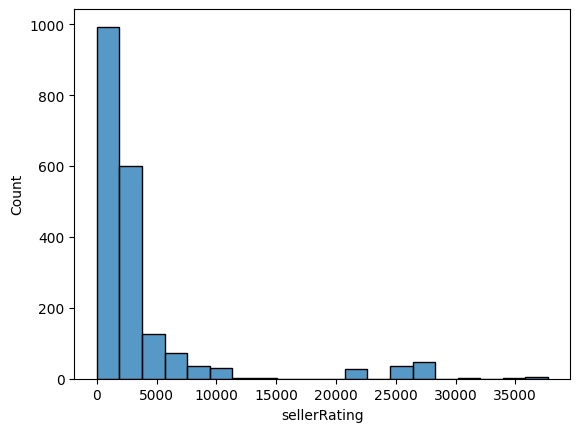

In [55]:
sns.histplot(data=ebay, x="sellerRating", bins=20)
plt.savefig("eBay Seller Rating.png")
plt.show()

In [56]:
ebay["endDay"].unique()

array(['Mon', 'Tue', 'Fri', 'Thu', 'Sat', 'Sun', 'Wed'], dtype=object)

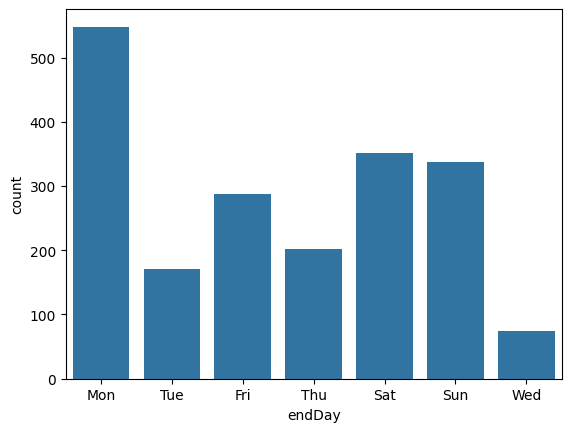

In [57]:
sns.countplot(data=ebay, x="endDay")
plt.savefig("eBay End Day.png")
plt.show()

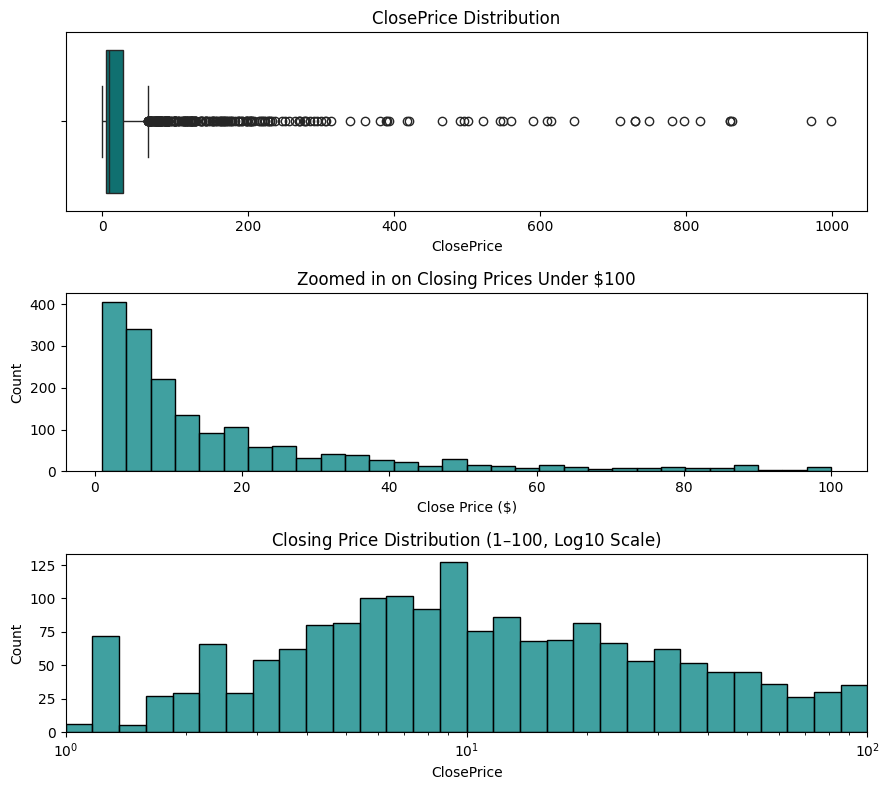

In [58]:
fig, axes = plt.subplots(3, figsize=(9,8))

sns.boxplot(data=ebay, x="ClosePrice", color="teal", ax=axes[0])
axes[0].set_title("ClosePrice Distribution")

sns.histplot(
    data=ebay,
    x="ClosePrice",
    bins=30,
    binrange=(1, 100),
    color="teal",
    ax=axes[1]
)
axes[1].set_title("Zoomed in on Closing Prices Under $100")
axes[1].set_xlabel("Close Price ($)")

sns.histplot(
    data=ebay,
    x="ClosePrice",    # Removed space to match exact column name
    bins=30,
    binrange=(0, 2),
    log_scale=True,
    color="teal",
    ax=axes[2]
)
axes[2].set_xlim(1, 100)
axes[2].set_title("Closing Price Distribution ($1 – $100, Log10 Scale)")

plt.tight_layout()
plt.savefig("eBay Close Price.png")
plt.show()


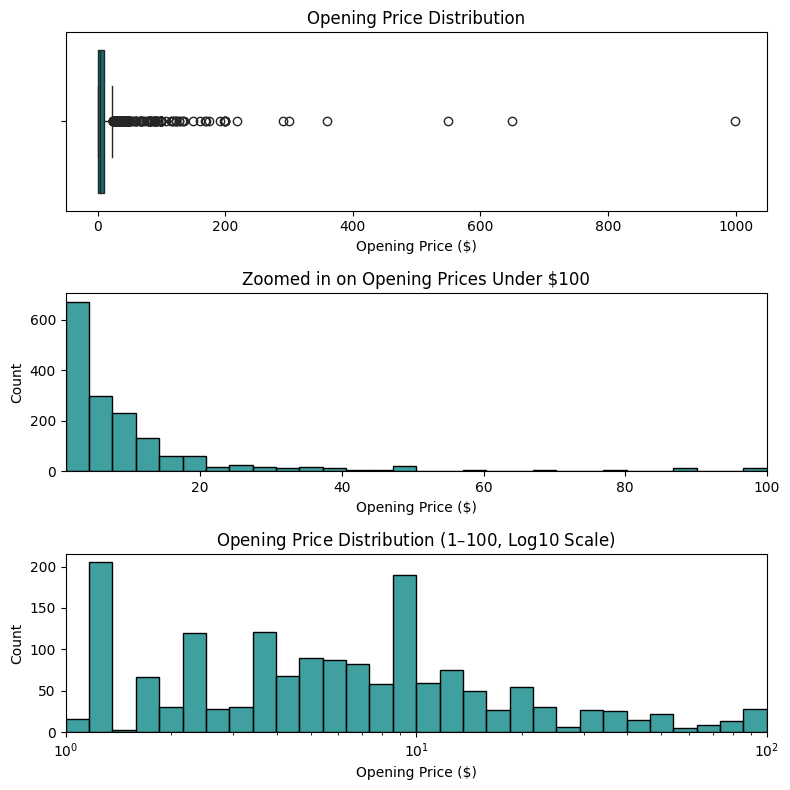

In [59]:
fig, axes = plt.subplots(3, 1, figsize=(8, 8))

# 1. Full distribution boxplot
sns.boxplot(data=ebay, x="OpenPrice", color="teal", ax=axes[0])
axes[0].set_title("Opening Price Distribution")
axes[0].set_xlabel("Opening Price ($)")

# 2. Zoomed linear histogram ($1 – $100)
sns.histplot(
    data=ebay,
    x="OpenPrice",        # Removed space to match column name
    bins=30,
    binrange=(1, 100),
    color="teal",
    ax=axes[1]
)
axes[1].set_xlim(1, 100)
axes[1].set_title("Zoomed in on Opening Prices Under $100")
axes[1].set_xlabel("Opening Price ($)")

# 3. Zoomed log10 histogram ($1 – $100)
sns.histplot(
    data=ebay,
    x="OpenPrice",
    bins=30,
    binrange=(0, 2),      # log10(1) = 0, log10(100) = 2
    log_scale=True,       # Base-10 logarithmic x-axis
    color="teal",
    ax=axes[2]
)
axes[2].set_xlim(1, 100)
axes[2].set_title("Opening Price Distribution ($1 – $100, Log10 Scale)")
axes[2].set_xlabel("Opening Price ($)")

plt.tight_layout()
plt.savefig("eBay Open Price.png")
plt.show()

In [60]:
ebay["Competitive?"].unique()

array([0, 1])

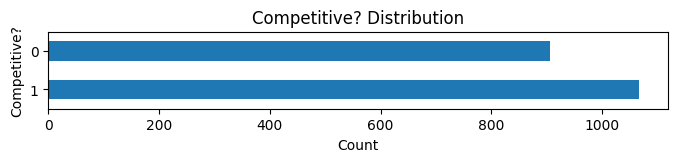

In [61]:
plt.figure(figsize=(8, 1))
ebay["Competitive?"].value_counts().plot.barh()
plt.title("Competitive? Distribution")
plt.xlabel("Count")
plt.ylabel("Competitive?")
plt.savefig("eBay Competitive.png")
plt.show()

In [62]:
ebay.columns


Index(['Category', 'currency', 'sellerRating', 'Duration', 'endDay',
       'ClosePrice', 'OpenPrice', 'Competitive?'],
      dtype='object')

In [63]:
trainData, validData = train_test_split(ebay, test_size=0.4, random_state=42)

In [64]:
trainData.head()

,Category,currency,sellerRating,Duration,endDay,ClosePrice,OpenPrice,Competitive?
857,Music/Movie/Game,EUR,286,5,Sat,33.82,1.23,1
711,Music/Movie/Game,EUR,1634,10,Wed,5.53,4.90,1
1245,Clothing/Accessories,EUR,595,5,Thu,110.53,1.23,1
1078,Antique/Art/Craft,EUR,266,3,Thu,62.09,1.23,1
1361,Collectibles,US,2220,3,Sat,115.27,0.99,1


Model A

In [65]:
def build_knn(num_cols, cat_cols, k):
    pre = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])
    return make_pipeline(pre, KNeighborsClassifier(n_neighbors=k))

def tune_knn(df, num_cols, cat_cols, target="Competitive?", ks=range(1, 31)):
    X_ = df[num_cols + cat_cols]
    y_ = df[target]
    Xtr, Xva, ytr, yva = train_test_split(X_, y_, test_size=0.4,
                                          random_state=42, stratify=y_)
    rows = []
    for k in ks:
        m = build_knn(num_cols, cat_cols, k).fit(Xtr, ytr)
        rows.append({"k": k, "Train accuracy": m.score(Xtr, ytr), "Validation accuracy": m.score(Xva, yva)})
    res = pd.DataFrame(rows)
    best = int(res.loc[res["Validation accuracy"].idxmax(), "k"])
    final = build_knn(num_cols, cat_cols, best).fit(Xtr, ytr)
    return res, best, final, (Xva, yva)

def plot_k_curve(res, best, title):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(res["k"], res["Train accuracy"], marker="o", ms=3, label="Train")
    ax.plot(res["k"], res["Validation accuracy"], marker="o", ms=3, label="Validation")
    ax.axvline(best, color="red", ls="--", label=f"Best k = {best}")
    ax.set_xlabel("k"); ax.set_ylabel("Accuracy"); ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.show()

Best k (all predictors): 1
Validation accuracy: 0.7503


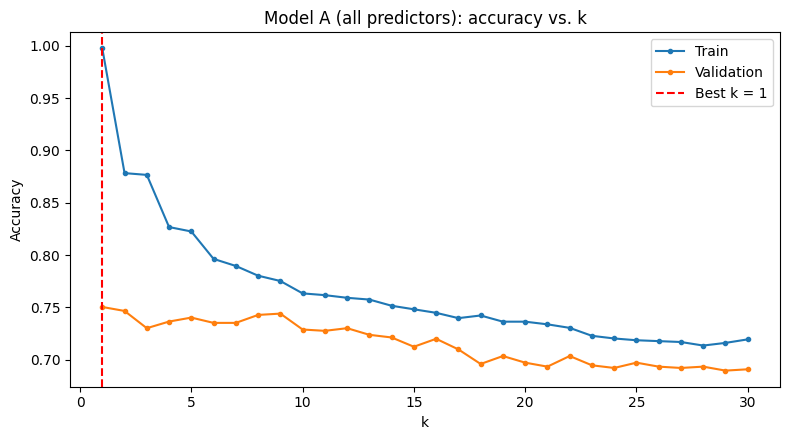

<Figure size 640x480 with 0 Axes>

In [66]:
all_num = ["sellerRating","OpenPrice", "ClosePrice"]
all_cat = ["Category", "currency", "endDay", "Duration"]
target = "Competitive?"

res_all, best_all, model_all, (Xva_all, yva_all) = tune_knn(ebay, all_num, all_cat)
print(f"Best k (all predictors): {best_all}")
print(f"Validation accuracy: {accuracy_score(yva_all, model_all.predict(Xva_all)):.4f}")
plot_k_curve(res_all, best_all, "Model A (all predictors): accuracy vs. k")
plt.savefig("eBay KNN a.png")

In [67]:
# Print columns to confirm only pre-auction predictors are included
predictors_a = X.columns.tolist()
print("Predictors used:", X.columns.tolist())

Predictors used: ['Age', 'Experience', 'Income', 'ZIP Code', 'Family', 'CCAvg', 'Education', 'Mortgage', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


I am not sure why I am not getting ClosePrice as the predictors used. ClosePrice would be something that you would want to predict.

Model B

Best k (all predictors): 12
Validation accuracy: 0.7313


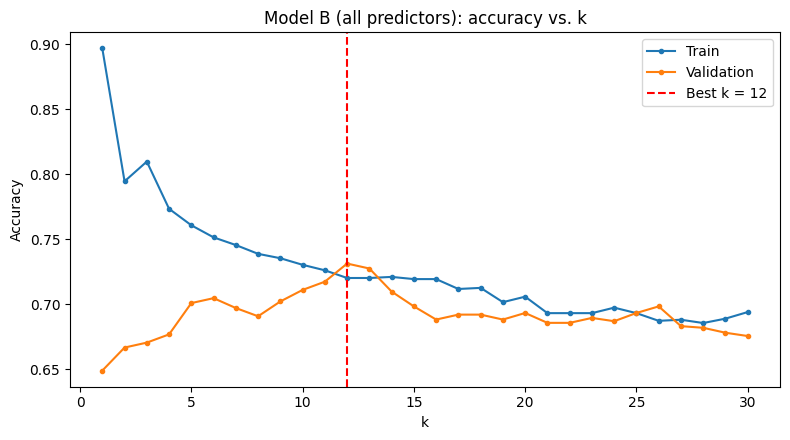

<Figure size 640x480 with 0 Axes>

In [68]:
all_num2 = ["sellerRating","OpenPrice"]
all_cat2 = ["Category", "currency", "endDay", "Duration"]


res_all, best_all, model_all, (Xva_all, yva_all) = tune_knn(ebay, all_num2, all_cat2)
print(f"Best k (all predictors): {best_all}")
print(f"Validation accuracy: {accuracy_score(yva_all, model_all.predict(Xva_all)):.4f}")
plot_k_curve(res_all, best_all, "Model B (all predictors): accuracy vs. k")
plt.savefig("eBay KNN b.png")

In [69]:
predictors_b = X.columns.tolist()

In [70]:
# Print columns to confirm only pre-auction predictors are included
print("Predictors used:", X.columns.tolist())

Predictors used: ['Age', 'Experience', 'Income', 'ZIP Code', 'Family', 'CCAvg', 'Education', 'Mortgage', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


Model C

Best k (all predictors): 12
Validation accuracy: 0.9434


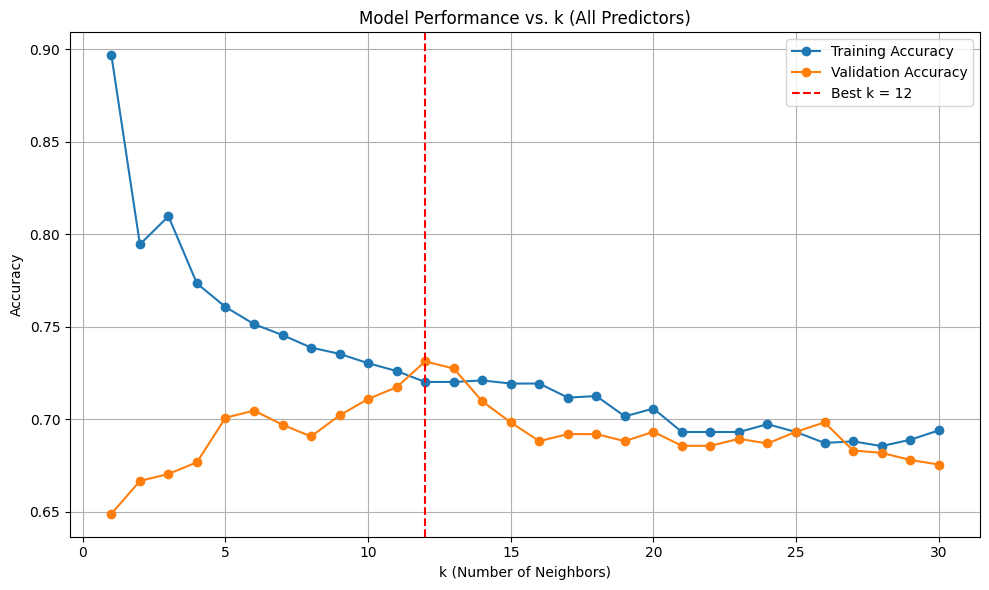

In [71]:
# Identify the best k based on validation accuracy
best_all = int(res_all.loc[res_all["Validation accuracy"].idxmax(), "k"])

# Build and fit final model using the best k
model_all = KNeighborsClassifier(n_neighbors=best_all).fit(X_train_scaled, y_train)
Xva_all, yva_all = X_valid_scaled, y_valid

# Print Results
print(f"Best k (all predictors): {best_all}")
print(f"Validation accuracy: {accuracy_score(yva_all, model_all.predict(Xva_all)):.4f}")

# Plot the accuracy curve
plt.figure(figsize=(10, 6))
plt.plot(res_all["k"], res_all["Train accuracy"], marker="o", label="Training Accuracy")
plt.plot(res_all["k"], res_all["Validation accuracy"], marker="o", label="Validation Accuracy")
plt.axvline(best_all, color="red", linestyle="--", label=f"Best k = {best_all}")
plt.xlabel("k (Number of Neighbors)")
plt.ylabel("Accuracy")
plt.title("Model Performance vs. k (All Predictors)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("eBay KNN c.png")
plt.show()

In [72]:
predictors_c = X.columns.tolist()

In [73]:
# Print columns to confirm only pre-auction predictors are included
print("Predictors used:", X.columns.tolist())

Predictors used: ['Age', 'Experience', 'Income', 'ZIP Code', 'Family', 'CCAvg', 'Education', 'Mortgage', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


No. There are two problems with including ClosePrice:

ClosePrice is not known when a new auction starts. It is determined only at the end of the auction, so Model A cannot be used to predict a future auction. Its validation accuracy (about 0.75) is only about 2 points higher than Model B (about 0.73), and that gain comes entirely from ClosePrice. I am not sure what I did differently in Model C, but it's much more accurate than Model A & B. I think is that I didn't use dummy variables or that just the code is different. If you could take a look at it an let me know what I would appreciate it. I think it's because I used a different approach and that that approach was obviously better since it has an accuracy of .94.  The model A is not deployable  whatever its accuracy is, because ClosePrice is determined by the bidding that defines Competitive?.
Duration, OpenPrice, currency, and endDay are known at listing time. The seller chooses them, so they can be used. Keeping them is not a leakage problem unlike ClosePrice

The Revised approach was to remove ClosePrice and use only predictors known when the auction is listed. Also consided was how sellerRating (known before the auction starts) relates to competition.

When comparing all models it would seem that models.